In [1]:
import torch

print(torch.__version__)

2.14.1+cpu


In [2]:
import matplotlib.pyplot as plt

from PIL import Image

from torchvision.models import (
    MobileNet_V2_Weights,
    mobilenet_v2
)

print("Libraries imported successfully.")

Libraries imported successfully.


In [3]:
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Using device:", device)

Using device: cpu


In [4]:
weights = MobileNet_V2_Weights.DEFAULT

model = mobilenet_v2(
    weights=weights
)

model = model.to(device)
model.eval()

print("MobileNetV2 loaded successfully.")

MobileNetV2 loaded successfully.


In [5]:
total_parameters = sum(
    parameter.numel()
    for parameter in model.parameters()
)

trainable_parameters = sum(
    parameter.numel()
    for parameter in model.parameters()
    if parameter.requires_grad
)

print("Model: MobileNetV2")
print("Framework: PyTorch")
print("Device:", device)
print("Number of classes:", 1000)
print("Total parameters:", f"{total_parameters:,}")
print(
    "Trainable parameters:",
    f"{trainable_parameters:,}"
)
print("Input size: 224 x 224 RGB")
print("Dataset: ImageNet-1K")

Model: MobileNetV2
Framework: PyTorch
Device: cpu
Number of classes: 1000
Total parameters: 3,504,872
Trainable parameters: 3,504,872
Input size: 224 x 224 RGB
Dataset: ImageNet-1K


In [6]:
preprocess = weights.transforms()

print("Preprocessing pipeline:")
print(preprocess)

Preprocessing pipeline:
ImageClassification(
    crop_size=[224]
    resize_size=[232]
    mean=[0.485, 0.456, 0.406]
    std=[0.229, 0.224, 0.225]
    interpolation=InterpolationMode.BILINEAR
)


In [7]:
class_names = weights.meta["categories"]

print("Total ImageNet classes:", len(class_names))

print("\nFirst 10 classes:")

for class_name in class_names[:10]:
    print("-", class_name)

Total ImageNet classes: 1000

First 10 classes:
- tench
- goldfish
- great white shark
- tiger shark
- hammerhead
- electric ray
- stingray
- cock
- hen
- ostrich


In [8]:
def predict_image(image_path, top_k=5):

    image = Image.open(
        image_path
    ).convert("RGB")

    input_tensor = preprocess(
        image
    ).unsqueeze(0).to(device)

    with torch.inference_mode():

        output = model(
            input_tensor
        )

        probabilities = torch.nn.functional.softmax(
            output[0],
            dim=0
        )

        top_probabilities, top_indices = torch.topk(
            probabilities,
            k=top_k
        )

    predictions = []

    for probability, index in zip(
        top_probabilities,
        top_indices
    ):

        predictions.append(
            (
                class_names[index.item()],
                probability.item() * 100
            )
        )

    return image, predictions


print("Prediction function created successfully.")

Prediction function created successfully.


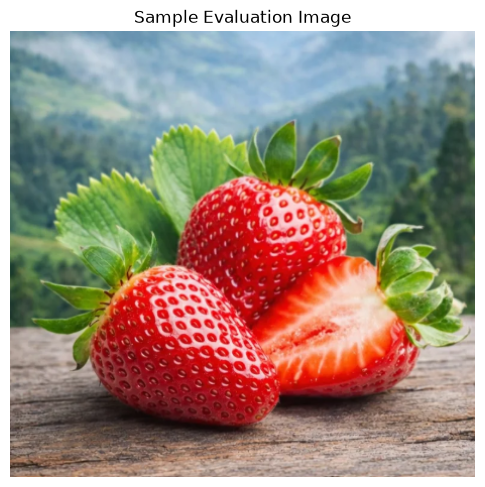

Top-5 Predictions:

1. strawberry: 47.54%
2. orange: 0.33%
3. banana: 0.32%
4. tray: 0.29%
5. ice cream: 0.29%


In [9]:
image_path = "../evaluation/strawberry/strawberry1.png"

image, predictions = predict_image(
    image_path
)

plt.figure(figsize=(6, 6))
plt.imshow(image)
plt.axis("off")
plt.title("Sample Evaluation Image")
plt.show()

print("Top-5 Predictions:\n")

for rank, (class_name, confidence) in enumerate(
    predictions,
    start=1
):
    print(
        f"{rank}. {class_name}: "
        f"{confidence:.2f}%"
    )

## Official Pretrained Model Metrics

The MobileNetV2 pretrained ImageNet-1K weights used in this project have the following official benchmark metrics:

- **Top-1 Accuracy:** 72.154%
- **Top-5 Accuracy:** 90.822%

These are the official benchmark values associated with the pretrained ImageNet-1K weights.

They are separate from the custom evaluation performed for this project.

## Custom Evaluation Results

A custom evaluation dataset containing **25 images** was created using five ImageNet-1K classes:

| Class | Images |
|---|---:|
| Strawberry | 5 |
| Banana | 5 |
| Pineapple | 5 |
| Lemon | 5 |
| Orange | 5 |
| **Total** | **25** |

The pretrained MobileNetV2 model was evaluated without additional fine-tuning.

### Results

- **Top-1 Accuracy:** 100.00%
- **Top-5 Accuracy:** 100.00%

All 25 images were correctly classified in the Top-1 prediction.

> **Note:** The 100% result applies only to this small custom 25-image evaluation set. It should not be interpreted as the model's general ImageNet-1K accuracy.

## Confusion Matrix

The confusion matrix below was generated from the 25-image custom evaluation dataset.

![MobileNetV2 Confusion Matrix](../screenshots/confusion_matrix.png)

The diagonal values show that all 25 images were correctly classified by the model in the Top-1 prediction.

## Conclusion

This project demonstrates an end-to-end image classification system using a pretrained MobileNetV2 convolutional neural network.

The model was integrated with a FastAPI backend that accepts image uploads and returns the Top-5 predicted classes with confidence scores.

The web interface provides:

- Drag-and-drop image upload
- Image preview
- Top-5 predictions
- Confidence visualization
- Prediction history
- Error handling

The custom evaluation achieved 100.00% Top-1 and 100.00% Top-5 accuracy on the selected 25-image evaluation set.

The official ImageNet-1K benchmark metrics for the pretrained MobileNetV2 weights are reported separately to avoid confusing the custom evaluation results with the model's official benchmark performance.